# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: NOMBRE DEL GRUPO

# Integrantes
* integrante
* integrante

In [17]:
import cv2
import numpy as np
import alcMODULOfinal as alc
from matplotlib import pyplot as plt

### Ejercicio 1. DLT: ecuaciones formales

Buscamos la matriz de proyección $M$ que relaciona puntos conocidos del espacio real de tres dimensiones con sus proyecciones tambien conocidas en una imagen.

Tenemos de $n$ correspondencias de un mismo objeto. Para cada correspondencia $i$, sabemos:

- $(U_i,V_i,W_i)$: las coordenadas del punto en el sistema del mundo.
- $(u_i,v_i)$: las coordenadas de su proyección en la imagen, medidas en píxeles.

Una correspondencia vincula un punto del mundo real con su proyección en la imagen. 


**Como vinculamos estos puntos? **
Bueno, esto es desarrollado a partir de la informacion del marco teorico del trabajo practico. 

Escribimos el punto del mundo en sus coordenadas:

$$
P_i=
\begin{pmatrix}
U_i\\V_i\\W_i\\1
\end{pmatrix}.
$$

El $1$ es agregado para incorporar la traslación (t) al producto matricial. 

La relación entre las coordenadas del mundo y las coordenadas de cámara es:

$$
\begin{pmatrix}
X_i\\Y_i\\Z_i
\end{pmatrix}
=
[R\mid t]P_i,
$$

donde $R\in\mathbb R^{3\times3}$ es la matriz de rotación y $t\in\mathbb R^3$ es el vector de traslación. La notación $[R\mid t]$ representa la matriz de $3\times4$ formada al agregar $t$ como cuarta columna de $R$.

Las coordenadas $(U_i,V_i,W_i)$ y $(X_i,Y_i,Z_i)$ describen el mismo punto físico respecto de dos sistemas de referencia diferentes, el primero del mundo real y el segundo de la camara.

La relación entre las coordenadas de cámara y las coordenadas de imagen es:

$$
\lambda_i
\begin{pmatrix}
u_i\\v_i\\1
\end{pmatrix}
=
K
\begin{pmatrix}
X_i\\Y_i\\Z_i
\end{pmatrix},
$$

donde $K\in\mathbb R^{3\times3}$ contiene los parámetros intrínsecos de la cámara y $\lambda_i$ es el factor de escala.


Sustituyendo la primera relación en la segunda:

$$
\lambda_i
\begin{pmatrix}
u_i\\v_i\\1
\end{pmatrix}
=
K[R\mid t]P_i.
$$

Ahora bien, definimos la matriz de proyección:

$$
M=K[R\mid t]
=
\begin{pmatrix}
m_{11}&m_{12}&m_{13}&m_{14}\\
m_{21}&m_{22}&m_{23}&m_{24}\\
m_{31}&m_{32}&m_{33}&m_{34}
\end{pmatrix}
\in\mathbb R^{3\times4}.
$$

Y de este modo obtenemos:

$$
\boxed{
\lambda_i
\begin{pmatrix}
u_i\\v_i\\1
\end{pmatrix}
=MP_i.
}
$$

La relacion entre los puntos del mundo real y los puntos en la imagen. 
Las doce componentes de $M$ condensan la información de $K,R,t$ y son las incógnitas que debemos encontrar.

Desarrollando el producto matricial obtenemos el siguiente sistema de ecuaciones:

$$
\begin{aligned}
\lambda_i u_i
&=m_{11}U_i+m_{12}V_i+m_{13}W_i+m_{14},\\
\lambda_i v_i
&=m_{21}U_i+m_{22}V_i+m_{23}W_i+m_{24},\\
\lambda_i
&=m_{31}U_i+m_{32}V_i+m_{33}W_i+m_{34}.
\end{aligned}
$$

Si reemplazamos $\lambda_i$, usando la tercera ecuación, en las ecuaciones de $u_i$ y $v_i$ y llevamos todos los términos al mismo lado:

$$
\begin{aligned}
0={}&m_{11}U_i+m_{12}V_i+m_{13}W_i+m_{14}\\
&-u_i m_{31}U_i-u_i m_{32}V_i-u_i m_{33}W_i-u_i m_{34},
\end{aligned}
$$

$$
\begin{aligned}
0={}&m_{21}U_i+m_{22}V_i+m_{23}W_i+m_{24}\\
&-v_i m_{31}U_i-v_i m_{32}V_i-v_i m_{33}W_i-v_i m_{34}.
\end{aligned}
$$

Así, cada correspondencia de puntos aporta dos ecuaciones lineales en las entradas de $M$.


Ordenamos las incógnitas por filas de $M$:

$$
m=
\begin{pmatrix}
m_{11}&m_{12}&m_{13}&m_{14}&
m_{21}&m_{22}&m_{23}&m_{24}&
m_{31}&m_{32}&m_{33}&m_{34}
\end{pmatrix}^{T}
\in\mathbb R^{12}.
$$

Siendo $m$ el vector de coeficientes de la matriz de proyección.


Para cada correspondencia definimos el bloque:

$$
Q_i=
\begin{pmatrix}
U_i&V_i&W_i&1&0&0&0&0&
-u_iU_i&-u_iV_i&-u_iW_i&-u_i\\
0&0&0&0&U_i&V_i&W_i&1&
-v_iU_i&-v_iV_i&-v_iW_i&-v_i
\end{pmatrix}
\in\mathbb R^{2\times12}.
$$


Apilando los bloques de las $n$ correspondencias:

$$
\boxed{
Q=
\begin{pmatrix}
Q_1\\Q_2\\\vdots\\Q_n
\end{pmatrix}
\in\mathbb R^{2n\times12},
\qquad Qm=0.
}
$$

Esta es la construcción de la ecuación 6 que se marca en el TP. La matriz $Q$ contiene todos los datos conocidos, mientras que $m$ contiene las doce incógnitas.


**Construccion de Q a partir de los datos de `calib/3d`**

`p_W_corners.txt` tiene doce filas, cada una con las coordenadas $(U_i,V_i,W_i)$ de un punto del mundo real.

`detected_corners.txt` contiene 210 filas de 24 valores. Cada fila agrupa doce pares de coordenadas de imagen, en el orden:

$$
u_1,v_1,u_2,v_2,\ldots,u_{12},v_{12}.
$$

Estos doce pares, corresponden al mismo punto del mundo real, en coordenadas de la imagen. El primer par de puntos de la imagen correponde al primer punto del mundo real. Tenemos 12 pares de coordenadas que corresponden a los 12 puntos del mundo real. Estos 12 pares de coordenadas son las proyecciones en la imagen de los 12 puntos. 

Para armar un ejemplo del sistema tomamos la primera fila de detecciones, que es utilizado en el notebook `chequeo_puntos_3d.ipynb` que corresponde a `img_0001.jpg`.

Matcheamos el punto de la fila $i$ de `p_W_corners.txt` con el par $i$ de esa primera observación. Este match supone que ambas listas conservan el mismo orden de marcas. O sea la primer fila de `detected_corners.txt` corresponde a la `img_0001.jpg`, y la fila 50 corresponde a la imagen 50. 

Numeramos las correspondencias del 1 al 12:

| $i$ | $U_i$ | $V_i$ | $W_i$ | $u_i$ | $v_i$ |
|---:|---:|---:|---:|---:|---:|
| 1 | 0 | 8 | 0 | 186.5 | 187.5 |
| 2 | 10.4 | 8 | 0 | 264.5 | 166.5 |
| 3 | 0 | 21.5 | 0 | 218.5 | 304.5 |
| 4 | 10.4 | 21.5 | 0 | 285.5 | 270.5 |
| 5 | 0 | 26.6 | -10.95 | 292.5 | 369.5 |
| 6 | 10.4 | 26.6 | -10.95 | 356.5 | 322.5 |
| 7 | 0 | 26.6 | -24.45 | 406.5 | 418.5 |
| 8 | 10.4 | 26.6 | -24.45 | 461.5 | 353.5 |
| 9 | 19.4 | 14.6 | -10.95 | 388.5 | 204.5 |
| 10 | 19.4 | 14.6 | -24.45 | 495.5 | 211.5 |
| 11 | 19.4 | 25 | -10.95 | 396.5 | 280.5 |
| 12 | 19.4 | 25 | -24.45 | 496.5 | 300.5 |

Las coordenadas del mundo mantienen las unidades del archivo; las coordenadas de la imagen están en píxeles.

Por ejemplo, para la primera correspondencia:

$$
P_1=
\begin{pmatrix}0\\8\\0\\1\end{pmatrix},
\qquad
(u_1,v_1)=(186.5,187.5),
$$

obtenemos:

$$
Q_1=
\begin{pmatrix}
0&8&0&1&0&0&0&0&0&-1492&0&-186.5\\
0&0&0&0&0&8&0&1&0&-1500&0&-187.5
\end{pmatrix}.
$$

Construimos las demas ecuaciones, que son las correspondencias, de la misma manera. 

El sistema para esta primer imagen queda determinado por:

$$
\boxed{
Q=
\begin{pmatrix}
Q_1\\Q_2\\\vdots\\Q_{12}
\end{pmatrix}
\in\mathbb R^{24\times12},
\qquad Qm=0.
}
$$


a) Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Buscamos una solución no trivial y única salvo un factor de escala.


Primero quiero aclarar que “única a menos de un factor de escala” significa que todas las soluciones no nulas son múltiplos de un mismo vector, este unico vector es el que buscamos. Entonces si solo buscamos una solucion que resuelva el sistema homogeneo: 

$$
\dim(Nucleo Q)=1.
$$

Y como $Q$ tiene doce columnas, por el teorema de la Dimension visto en clase teorica con Daniel:

$$
\dim(Imagen Q)+\dim(Nucleo Q)=12.
$$

Por lo tanto:

$$
\boxed{\operatorname{rango}(Q)=11.}
$$

Esta condición es la condicion sistema homogéneo tenga una solución no nula única salvo un factor de escala.

- Si el rango es menor que 11, el núcleo tiene dimensión mayor que uno y existen mas soluciones no triviales.
- Si el rango es 11, el núcleo tiene dimensión uno: todas las soluciones son múltiplos de un mismo vector, el que nos interesa.
- Si el rango es 12, el núcleo contiene solamente al vector cero.

**Cantidad mínima de correspondencias**

Cada correspondencia punto a punto, aporta dos filas a $Q$. Como el rango no puede superar la cantidad de filas:

$$
11=\operatorname{rango}(Q)\leq2n.
$$

Entonces:

$$
n\geq\frac{11}{2}.
$$

Como $n$ es entero:

$$
\boxed{n_{\min}=6.}
$$

Seis correspondencias son el mínimo teorico posible, pero no cualquier conjunto de seis puntos garantiza que exista la solución. Las ecuaciones que aporta cada correspondencia debe aportar informacion no redundante.

Con seis correspondencias, $Q$ tiene doce filas. En el caso de rango 11, pueden seleccionarse once filas linealmente independientes, y la restante es combinación lineal de las otras 11.

La independencia es en las filas de $Q$, que son vectores de $\mathbb R^{12}$.

**Condición geométrica**

La condicion geometrica que deben cumplir los puntos, es que no deben pertenecer todos al mismo plano, es decir, no ser coplanarios. Pues, supongamos que lo sean: Entonces podemos elegir en el sistema de coordenadas del mundo real de manera que ese plano (donde pertenecen los puntos) sea $W=0$.

Entonces:

$$
W_i=0
\qquad\text{para todos los puntos}.
$$

En las ecuaciones de nuestro sistema, desaparecerian los factores $m_{13},m_{23},m_{33}$, porque siempre están multiplicadas por $W_i=0$. Por ejemplo:

$$
\lambda_i u_i
=m_{11}U_i+m_{12}V_i+m_{14}.
$$

Esos datos no permiten determinar la tercera columna de $M$. En $Q$, las columnas correspondientes a esas tres incógnitas quedan en cero, por lo tanto se afecta su rango:

$$
\operatorname{rango}(Q)\leq9<11.
$$

De este modo los puntos al ser coplanares no permiten recuperar la matriz que buscamos. Por lo tanto, los puntos 3D no pueden estar todos en un mismo plano. 


Finalmente, la respuesta a este inciso es:

$$
\boxed{
\begin{gathered}
\operatorname{rango}(Q)=11,\\
\text{mínimo seis puntos.}
\end{gathered}
}
$$

b) Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Como dice el TP, con datos reales, que tienen ruido, errores de localizacion, etc. Producen que generalmente no exista ningún $m\neq0$ que satisfaga exactamente $Qm=0$. En ese caso buscamos un vector que minimice esto:

$$
\boxed{
\min_{\|m\|_2=1}\|Qm\|_2^2.
}
$$

Que si manipulamos la expresion con algunas tecnicas de la teorica:

$$
\|Qm\|_2^2
=(Qm)^T(Qm)
=m^TQ^TQm.
$$

Que es el resultado de la ecuacion 8 en el TP:

$$
\boxed{
\min_{\|m\|_2=1}m^TQ^TQm.
}
$$

**Resolución mediante SVD**

Las diapositivas recomiendan que la solucion sale de plantear SVD de Q, entonces eso hacemos

$$
Q=U\Sigma V^T.
$$

Para $n\geq6$ (que es lo minimo teorico), sus dimensiones son:

$$
U\in\mathbb R^{2n\times2n},
\qquad
\Sigma\in\mathbb R^{2n\times12},
\qquad
V\in\mathbb R^{12\times12}.
$$

Las matrices $U,V$ son ortogonales y $\Sigma$ es diagonal rectangular. Ordenamos los doce valores singulares de mayor a menor, incluyendo los que puedan ser cero:

$$
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_{12}\geq0.
$$


Como $U^TU=I$:

$$
\begin{aligned}
\|Qm\|_2^2
&=\|U\Sigma V^Tm\|_2^2\\
&=(\Sigma V^Tm)^TU^TU(\Sigma V^Tm)\\
&=(\Sigma V^Tm)^T(\Sigma V^Tm)\\
&=\|\Sigma V^Tm\|_2^2.
\end{aligned}
$$


Como $\Sigma$ multiplica cada componente por el valor singular correspondiente:

$$
\|Qm\|_2^2
=
\sum_{j=1}^{12}
\sigma_j^2\bigl((V^Tm)_j\bigr)^2,
$$

donde $(V^Tm)_j$ es la componente $j$ del vector $V^Tm$.

Entonces, para cualquier de nuestros candidatos que cumpla $\|m\|_2=1$:

$$
\sum_{j=1}^{12}\bigl((V^Tm)_j\bigr)^2
=
\|V^Tm\|_2^2
=
\|m\|_2^2
=1.
$$

Como todos los valores singulares son mayores o iguales que $\sigma_{12}$:

$$
\begin{aligned}
\|Qm\|_2^2
&=\sum_{j=1}^{12}
\sigma_j^2\bigl((V^Tm)_j\bigr)^2\\
&\geq
\sigma_{12}^2
\sum_{j=1}^{12}\bigl((V^Tm)_j\bigr)^2\\
&=\sigma_{12}^2.
\end{aligned}
$$

Así demostramos que ningún vector unitario puede producir un valor menor que $\sigma_{12}^2$.
Esta demostracion tiene el mismo esqueleto que uso Daniel para demostrar que el primer valor singular correponde al valor de la norma 2. Como aca buscamos el min y no el max, nos quedamos con el ultimo valor singular. En nuestro caso por las dimensiones con las que trabajamos, es $\sigma_{12}$. 

Entonces, tenemos que encontrar $m$ asociado a ese sigma. Para ello elegimos $m$ de la siguiente manera:

$$
V^Tm=
\begin{pmatrix}
0\\\vdots\\0\\1
\end{pmatrix}.
$$

De esta forma solo sobrevive el ultimo, que vale $\sigma_{12}^2$.

Multiplicando por $V$ y usando $VV^T=I$:

$$
m=
V\begin{pmatrix}
0\\\vdots\\0\\1
\end{pmatrix}
=v_{12},
$$

donde $v_{12}$ es la última columna de $V$. Esta columna tiene norma uno porque $V$ es ortogonal, de modo que cumple la restricción.

Obtuvimos una cota inferior para todos los candidatos y encontramos un candidato que la alcanza. Por lo tanto, nuestro vector $m$ que resuelve la minimización es:

$$
\boxed{m_{\text{min}}=v_{12}.}
$$

El valor mínimo es:

$$
\boxed{
\min_{\|m\|_2=1}\|Qm\|_2^2=\sigma_{12}^2.
}
$$

**Relación con los autovectores de $Q^TQ$**

Este es el planteo que vamos a usar para la implementacion. 

A partir de la misma factorización:

$$
\begin{aligned}
Q^TQ
&=(U\Sigma V^T)^T(U\Sigma V^T)\\
&=V\Sigma^TU^TU\Sigma V^T\\
&=V\Sigma^T\Sigma V^T.
\end{aligned}
$$

La matriz $\Sigma^T\Sigma$ es diagonal y contiene los valores:

$$
\sigma_1^2,\sigma_2^2,\ldots,\sigma_{12}^2.
$$

En consecuencia, para cada columna $v_j$ de $V$:

$$
Q^TQ\,v_j=\sigma_j^2v_j.
$$

Entonces, las columnas de $V$ son autovectores de $Q^TQ$, con autovalores $\sigma_j^2$. En particular:

$$
\boxed{
m_{\text{min}} \text{ es un autovector unitario de }Q^TQ
\text{ asociado a su menor autovalor}.
}
$$


### Ejercicio 2 - Calibración con puntos 3D

In [2]:
# Leemos los datos
# poner la ruta/path particular de cada uno
ruta = 'calib/3d'

objPts = np.loadtxt(ruta+'/p_W_corners.txt',delimiter=',')

det_corners = np.loadtxt(ruta+'/detected_corners.txt')
imgPts = det_corners[0, :].reshape(12, 2) # 12 Filas de 2 columnas 

"""
U, V, W = objPts[0]
print(U), print(V), print(W)
print(objPts)
print(imgPts)
"""

'\nU, V, W = objPts[0]\nprint(U), print(V), print(W)\nprint(objPts)\nprint(imgPts)\n'

a) Implementar la función obtenerQ3d(imgPts, objPts) que devuelve la matriz Q a partir de la ecuación correspondiente.

In [ ]:
# Bueno, lo vamos a hacer para 1 imagen, para la imagen 1. Despues lo podemos hacer para las 210 si queremos. 
def obtenerQ3d(imgPts, objPts):
    n = imgPts.shape[0]
    Q = np.zeros((2*n,12))

    for i in range(n): 

        U, V, W = objPts[i,0], objPts[i,1], objPts[i,2]
        u, v = imgPts[i]

        ecuacionRespecto_u = 2*i
        ecuacionRespecto_v = 2*i + 1 

        Q[ecuacionRespecto_u] = [ U, V, W, 1, 
                                  0, 0, 0, 0, 
                               -u*U, -u*V, -u*W, -u ]

        Q[ecuacionRespecto_v] = [ 0, 0, 0, 0,
                                  U, V, W, 1, 
                               -v*U, -v*V, -v*W, -v ]

    return Q

Q = obtenerQ3d(imgPts,objPts)

#print(Q)



b) A partir de lo resuelto en el Ejercicio 1 b), implementar la función resolverDLT3D(Q), que a partir de Q encuentra la matriz de proyección M.



In [4]:
# Como vimos en el ejercicio 1, la solucion viene de plantear SVD, pero no necesitamos todo lo de SVD, necesitamos algunas cosas nada mas. Vamos a calcular lo que
# necesitamos, que es encontrar el autovector asociado al menor de los autovalores

def resolverDLT3D(Q):

    Q_traspuesta = alc.trasponer(Q)
    A = alc.mult_matricial(Q_traspuesta, Q)
    
    V, D = alc.diagRH(A)

    autoval_min = 0
    for j in range(1, D.shape[0]):
        if D[j, j] < D[autoval_min, autoval_min]:
            autoval_min = j

    m = V[:, autoval_min]
    M = m.reshape(3, 4)

    return M
M = resolverDLT3D(Q)
#print(M)

c) Una vez recuperada M, se la descompone en la matriz de parámetros intrínsecos K, la matriz de rotación R y el vector de traslación t, 
imponiendo que R sea ortonormal (RRT = I). Para ello, implementar la función devolverMatricesCalibracion3d(M), que devuelva R, t y K.

### Ejercicio 3 - Calibración con puntos coplanares

In [22]:
det_corners_coplanar = np.loadtxt(r"calib/coplanar/detected_corners.txt")
imgPts_coplanar = det_corners_coplanar[2, :].reshape(77, 2) # 77 Filas de 2 columnas 

In [23]:
rgb = cv2.imread('calib/coplanar/Im_R_3.png')


In [24]:
X = det_corners_coplanar[:,0::2]
Y = det_corners_coplanar[:,1::2]

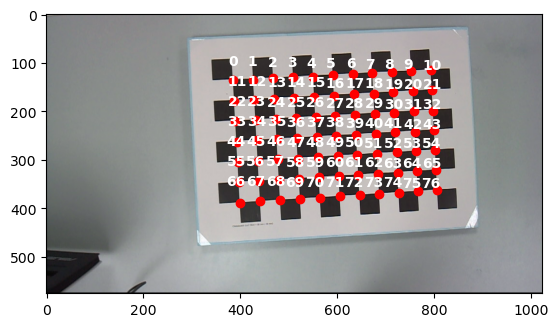

In [26]:
plt.imshow(rgb)
plt.plot(X[2,:], Y[2,:],'ro')
# Etiquetar cada punto con el número de su fila/índice
for i in range(len(X[0, :])):
    # (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
    plt.text(X[0, i] + 2, Y[0, i], str(i), color='white', fontsize=10, weight='bold')

plt.show()


Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

### Ejercicio 3 a) - Planteo

Hacemos un razonamiento análogo al del Ejercicio 1, pero ahora todos los puntos del mundo pertenecen a un mismo plano: el tablero de ajedrez. En el Ejercicio 1 a) vimos que justamente en este caso el DLT no funciona, porque las columnas de $W$ quedan en cero y $\operatorname{rango}(Q)\leq9<11$. Entonces hay que cambiar el planteo.

**Datos**

El tablero tiene $12\times8$ casillas de $30\,\text{mm}\times30\,\text{mm}$, o sea $11\times7=77$ esquinas internas. Como pide el enunciado, tomamos el origen en una esquina interna y los ejes $U,V$ a lo largo de los lados del tablero, con $W=0$. Así, las esquinas tienen coordenadas $(U,V)=(30\,i,\ 30\,j)$ mm, con $i=0,\dots,10$ y $j=0,\dots,6$. Estas coordenadas están en `calib/coplanar/p_W_corners.txt`, con el mismo formato que `calib/3d/p_W_corners.txt`: una fila $U, V, W$ por esquina, con la fila $n=11j+i$ igual a $(30\,i,\ 30\,j,\ 0)$. Es un solo archivo para las 10 imágenes, porque el sistema del mundo está pegado al tablero: lo que cambia de una imagen a otra es la pose de la cámara, no las coordenadas de las esquinas.

Las coordenadas $(u,v)$ de las esquinas en cada imagen están en `calib/coplanar/detected_corners.txt`, con el mismo formato que `calib/3d/detected_corners.txt`: una fila por imagen y 77 pares $(u,v)$ por fila. El par número $n=11j+i$ corresponde a la esquina $(30\,i,\ 30\,j)$. Este archivo lo generamos durante el desarrollo con las funciones de detección de esquinas de OpenCV, que no están permitidas en el código entregado.

**Paso 1: de la proyección a una homografía**

Para cada esquina del tablero:

$$
\lambda_i
\begin{pmatrix}u_i\\v_i\\1\end{pmatrix}
=K[r_1\ r_2\ r_3\mid t]
\begin{pmatrix}U_i\\V_i\\0\\1\end{pmatrix}
=K[r_1\ r_2\mid t]
\begin{pmatrix}U_i\\V_i\\1\end{pmatrix},
$$

donde $r_1,r_2,r_3$ son las columnas de $R$. La columna $r_3$ desaparece porque siempre está multiplicada por $W_i=0$. Definimos la homografía:

$$
\boxed{H=K[r_1\ r_2\mid t]\in\mathbb R^{3\times3}.}
$$

Es exactamente la misma cuenta del Ejercicio 1, pero sin la columna de $W$. Desarrollando el producto y despejando $\lambda_i$ con la tercera ecuación, cada correspondencia aporta el bloque:

$$
Q_i=
\begin{pmatrix}
U_i&V_i&1&0&0&0&-u_iU_i&-u_iV_i&-u_i\\
0&0&0&U_i&V_i&1&-v_iU_i&-v_iV_i&-v_i
\end{pmatrix}
\in\mathbb R^{2\times9},
$$

y apilando las $n$ correspondencias obtenemos la ecuación 11 del enunciado:

$$
\boxed{Q\,h=0,\qquad Q\in\mathbb R^{2n\times9},\qquad h=(h_{11},h_{12},h_{13},h_{21},\ldots,h_{33})^T\in\mathbb R^9.}
$$

**¿Qué rango debe tener $Q$?** Con el mismo argumento del Ejercicio 1 a), para que la solución sea única a menos de un factor de escala necesitamos $\dim(\operatorname{Nu}Q)=1$. Como $Q$ tiene 9 columnas, por el teorema de la dimensión:

$$
\boxed{\operatorname{rango}(Q)=8.}
$$

Como $8\leq2n$, hacen falta **al menos 4 puntos**, de los cuales no puede haber tres alineados. Cada imagen del tablero tiene 77 esquinas, así que sobran ecuaciones.

Con ruido no existe un $h\neq0$ que cumpla $Qh=0$ exactamente, así que resolvemos:

$$
\min_{\|h\|_2=1}\|Qh\|_2^2,
$$

y por lo demostrado en el Ejercicio 1 b), la solución es el **autovector de $Q^TQ$ asociado al menor autovalor**. Así obtenemos una homografía $H_j$ por cada imagen $j$.

**Paso 2: de las homografías a la matriz $A$**

Como $H$ está definida a menos de una escala, escribimos $[c_1\ c_2\ c_3]=s\,K[r_1\ r_2\mid t]$, donde $c_1,c_2,c_3$ son las columnas de $H$. Despejando:

$$
r_1=\tfrac1s K^{-1}c_1,\qquad r_2=\tfrac1s K^{-1}c_2.
$$

$R$ es ortogonal, así que sus columnas son ortonormales: $r_1^Tr_2=0$ y $\|r_1\|=\|r_2\|$. Reemplazando:

$$
c_1^TK^{-T}K^{-1}c_2=0,
\qquad
c_1^TK^{-T}K^{-1}c_1-c_2^TK^{-T}K^{-1}c_2=0.
$$

Estas ecuaciones solo dependen de la cámara, a través de la matriz

$$
B=K^{-T}K^{-1}=
\begin{pmatrix}
B_{11}&B_{12}&B_{13}\\
B_{12}&B_{22}&B_{23}\\
B_{13}&B_{23}&B_{33}
\end{pmatrix},
$$

que es simétrica, así que tiene solo 6 incógnitas: $b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^T$. Llamando $c_i=(c_{1i},c_{2i},c_{3i})^T$, cada producto $c_i^TBc_j$ es lineal en $b$:

$$
c_i^TBc_j=v_{ij}^Tb,\qquad
v_{ij}=
\begin{pmatrix}
c_{1i}c_{1j}\\
c_{1i}c_{2j}+c_{2i}c_{1j}\\
c_{2i}c_{2j}\\
c_{3i}c_{1j}+c_{1i}c_{3j}\\
c_{3i}c_{2j}+c_{2i}c_{3j}\\
c_{3i}c_{3j}
\end{pmatrix}.
$$

Entonces cada imagen aporta dos filas:

$$
\begin{pmatrix}
v_{12}^T\\
(v_{11}-v_{22})^T
\end{pmatrix}b=0,
$$

y apilando las $N$ imágenes:

$$
\boxed{A\,b=0,\qquad A\in\mathbb R^{2N\times6}.}
$$

Es otra vez un sistema homogéneo, y $b$ también está definido a menos de una escala. Con el mismo razonamiento del Ejercicio 1 a), necesitamos $\operatorname{rango}(A)=5$. Como $5\leq2N$, hacen falta **al menos 3 imágenes**, tomadas desde orientaciones distintas del tablero. Si el tablero está siempre en planos paralelos, las ecuaciones son redundantes. Nosotros tenemos 10 imágenes.

Y otra vez, por el Ejercicio 1 b), $b$ es el **autovector de $A^TA$ asociado al menor autovalor**.

**Paso 3: de $B$ a $K$ con Cholesky**

$b$ sale con un signo arbitrario, porque $-b$ también es autovector. Pero $B=K^{-T}K^{-1}$ es definida positiva, ya que $x^TBx=\|K^{-1}x\|^2>0$ para $x\neq0$. Entonces elegimos el signo que hace a $B$ definida positiva: si $B_{11}<0$, cambiamos $b$ por $-b$.

Como $B$ es simétrica definida positiva, tiene factorización de Cholesky $B=LL^T$, con $L$ triangular inferior con diagonal positiva. Por otro lado, $K^{-1}$ es triangular superior, así que $K^{-T}$ es triangular inferior y $B=K^{-T}(K^{-T})^T$. Por la unicidad de Cholesky:

$$
L=K^{-T}\quad\Longrightarrow\quad\boxed{K=(L^T)^{-1}.}
$$

Como $B$ se conoce a menos de una escala, al final dividimos $K$ por $K_{33}$ para que $K_{33}=1$.

Para calcular Cholesky usamos la factorización $LDV$ del módulo ALC. Si $B$ es simétrica, $B=L'DL'^T$ con $L'$ triangular inferior con unos en la diagonal. Si además es definida positiva, la diagonal de $D$ es positiva, así que $L=L'\sqrt D$.

**Detalle numérico: normalización (sección 2.3 del enunciado)**

Las coordenadas de la imagen llegan a $1024$ píxeles y las del tablero a $300$ mm. Entonces en las matrices conviven entradas de órdenes de magnitud muy distintos, y al armar $Q^TQ$ el número de condición se eleva al cuadrado, porque $\operatorname{cond}(Q^TQ)=\operatorname{cond}(Q)^2$.

- **En el Paso 1** usamos la normalización isotrópica de Hartley: una matriz $T$ que centra los puntos en el origen y los escala para que su distancia media al origen sea $\sqrt2$. Si $\check H$ es la homografía entre los puntos normalizados, deshacemos el cambio con $H=T_{img}^{-1}\,\check H\,T_{world}$ (ecuación 14). Con estos datos las homografías salen igual de bien sin normalizar, así que acá es una precaución.
- **En los Pasos 2 y 3 es imprescindible.** En píxeles, $B_{11}=1/\alpha_u^2\approx10^{-6}$ mientras que $B_{33}\approx1$. Lo probamos sin normalizar y el autovector sale tan impreciso que $B$ no da definida positiva. Por eso usamos una única matriz $T$ para todas las imágenes, que lleva los píxeles a $[-1,1]$, y trabajamos con $TH=(TK)[r_1\ r_2\mid t]$. Como $T$ es triangular superior, $\tilde K=TK$ también tiene la forma de una matriz de intrínsecos. Calculamos $\tilde K$ con los Pasos 2 y 3 y al final recuperamos $K=T^{-1}\tilde K$.


In [ ]:
# Ejercicio 3 a)
import os

ruta_coplanar = 'calib/coplanar'
esquinas_por_fila = 11    # esquinas internas a lo largo de U
esquinas_por_columna = 7  # esquinas internas a lo largo de V

# Coordenadas (U, V, W) de las esquinas en el sistema del tablero, en mm: la fila n = 11 j + i es (30 i, 30 j, 0).
# Son las mismas para todas las imágenes, porque el sistema del mundo está pegado al tablero.
objPts_coplanar = np.loadtxt(os.path.join(ruta_coplanar, 'p_W_corners.txt'), delimiter=',')
# Como W = 0 en todos los puntos, para la homografía alcanza con (U, V)
objPtsPlano = objPts_coplanar[:, :2]

# Coordenadas (u, v) de las esquinas en cada imagen: una fila por imagen (Im_R_1, Im_R_2, ...), 77 pares por fila
esquinas_detectadas = np.loadtxt(os.path.join(ruta_coplanar, 'detected_corners.txt'))
cantidad_imagenes = esquinas_detectadas.shape[0]
imgPtsPorImagen = [esquinas_detectadas[k, :].reshape(esquinas_por_fila*esquinas_por_columna, 2)
                   for k in range(cantidad_imagenes)]
nombres_imagenes = ['Im_R_' + str(k + 1) + '.png' for k in range(cantidad_imagenes)]

# Tamaño de las imágenes, para normalizar las coordenadas en píxeles
alto_imagen, ancho_imagen = cv2.imread(os.path.join(ruta_coplanar, nombres_imagenes[0])).shape[:2]


def autovectorMinimo(A):
    '''
    Calcula el autovector asociado al menor autovalor de una matriz simétrica,
    que por el Ejercicio 1 b) es la solución de min ||Qx|| con ||x|| = 1 cuando A = Q^T Q.
    Parámetros:
        A: matriz simétrica de n x n.
    Devuelve:
        vector de largo n, de norma 1.
    '''
    autovectores, autovalores = alc.diagRH(A)

    # Buscamos la posición del menor autovalor en la diagonal
    autoval_min = 0
    for j in range(1, autovalores.shape[0]):
        if autovalores[j, j] < autovalores[autoval_min, autoval_min]:
            autoval_min = j

    return autovectores[:, autoval_min]


def matrizNormalizacion(puntos):
    '''
    Arma la matriz de normalización isotrópica de Hartley (sección 2.3 del enunciado).
    Parámetros:
        puntos: array de n x 2 con coordenadas cartesianas.
    Devuelve:
        T: matriz de 3 x 3 que, en coordenadas homogéneas, lleva el centroide de los puntos
           al origen y los escala para que su distancia media al origen sea sqrt(2).
    '''
    centroide = np.mean(puntos, axis=0)
    distancia_media = np.mean(np.sqrt(np.sum((puntos - centroide)**2, axis=1)))
    escala = np.sqrt(2) / distancia_media
    return np.array([[escala, 0, -escala*centroide[0]],
                     [0, escala, -escala*centroide[1]],
                     [0, 0, 1]])


def aplicarTransformacion(T, puntos):
    '''
    Aplica una transformación proyectiva a un conjunto de puntos del plano.
    Parámetros:
        T: matriz de 3 x 3 (normalización u homografía).
        puntos: array de n x 2 con coordenadas cartesianas.
    Devuelve:
        array de n x 2 con los puntos transformados, en coordenadas cartesianas.
    '''
    # Pasamos a coordenadas homogéneas agregando una columna de unos
    puntos_homogeneos = np.hstack([puntos, np.ones((puntos.shape[0], 1))])

    # Aplicamos T a cada punto (como columnas) y volvemos a dejar un punto por fila
    transformados = alc.trasponer(alc.mult_matricial(T, alc.trasponer(puntos_homogeneos)))

    # Dividimos por la tercera coordenada para volver a coordenadas cartesianas
    return transformados[:, :2] / transformados[:, 2:]


def obtenerQ2d(imgPts, objPts):
    '''
    Arma la matriz Q de la ecuación 11 del enunciado, cuyo núcleo contiene a la homografía vectorizada
    h = (h1, h2, h3), donde h1^T, h2^T, h3^T son las filas de H.
    Parámetros:
        imgPts: array de n x 2 con las coordenadas (u, v) de los puntos en la imagen.
        objPts: array de n x 2 con las coordenadas (U, V) de los mismos puntos en el plano del tablero (W = 0).
    Devuelve:
        Q: matriz de 2n x 9.
    '''
    n = imgPts.shape[0]
    Q = np.zeros((2*n, 9))
    cero = np.zeros(3)

    for i in range(n):
        # Punto del tablero en coordenadas homogéneas: P_i = (U_i, V_i, 1)
        P_i = np.array([objPts[i, 0], objPts[i, 1], 1])
        u_i, v_i = imgPts[i]

        # Cada correspondencia aporta dos filas, con los bloques de la ecuación 11:
        #   [ P_i^T   0^T    -u_i P_i^T ]
        #   [ 0^T     P_i^T  -v_i P_i^T ]
        Q[2*i]     = np.hstack([P_i, cero, -u_i*P_i])
        Q[2*i + 1] = np.hstack([cero, P_i, -v_i*P_i])

    return Q


def estimarHomografia(imgPts, objPts):
    '''
    Estima la homografía H que lleva los puntos del tablero a la imagen, usando DLT con normalización isotrópica.
    Parámetros:
        imgPts: array de n x 2 con las coordenadas (u, v) en la imagen.
        objPts: array de n x 2 con las coordenadas (U, V) en el tablero.
    Devuelve:
        H: matriz de 3 x 3 con H[2, 2] = 1.
    '''
    # Normalizamos ambos conjuntos de puntos
    T_img = matrizNormalizacion(imgPts)
    T_world = matrizNormalizacion(objPts)
    imgPts_norm = aplicarTransformacion(T_img, imgPts)
    objPts_norm = aplicarTransformacion(T_world, objPts)

    # DLT sobre los puntos normalizados: h es el autovector de Q^T Q con menor autovalor
    Q = obtenerQ2d(imgPts_norm, objPts_norm)
    h = autovectorMinimo(alc.mult_matricial(alc.trasponer(Q), Q))
    H_norm = h.reshape(3, 3)

    # Deshacemos la normalización (ecuación 14): H = T_img^-1 H_norm T_world
    H = alc.mult_matricial(alc.mult_matricial(alc.inversa(T_img), H_norm), T_world)
    return H / H[2, 2]


def vectorV(H, i, j):
    '''
    Arma el vector v_ij que cumple c_i^T B c_j = v_ij^T b, siendo c_i y c_j columnas de H.
    Parámetros:
        H: homografía de 3 x 3.
        i, j: índices (0, 1 o 2) de las columnas de H.
    Devuelve:
        vector de largo 6.
    '''
    ci, cj = H[:, i], H[:, j]
    return np.array([ci[0]*cj[0],
                     ci[0]*cj[1] + ci[1]*cj[0],
                     ci[1]*cj[1],
                     ci[2]*cj[0] + ci[0]*cj[2],
                     ci[2]*cj[1] + ci[1]*cj[2],
                     ci[2]*cj[2]])


def armarA(Hlst):
    '''
    Arma la matriz A del sistema A b = 0, con dos filas por cada homografía.
    Parámetros:
        Hlst: lista de N homografías de 3 x 3, una por imagen.
    Devuelve:
        A: matriz de 2N x 6.
    '''
    filas = []
    for H in Hlst:
        # Llevamos H a norma 1 para que todas las imágenes pesen lo mismo en el sistema
        H = H / alc.norma(H.reshape(9), 2)
        filas.append(vectorV(H, 0, 1))                    # r1^T r2 = 0
        filas.append(vectorV(H, 0, 0) - vectorV(H, 1, 1))  # ||r1|| = ||r2||
    return np.array(filas)


def cholesky(B):
    '''
    Calcula la factorización de Cholesky B = L L^T a partir de la factorización LDV del módulo ALC.
    Parámetros:
        B: matriz simétrica definida positiva de n x n.
    Devuelve:
        L: matriz triangular inferior con diagonal positiva.
    '''
    # Como B es simétrica, B = L' D L'^T, con L' triangular inferior con unos en la diagonal
    L_unos, D, _ = alc.calculaLDV(B)

    # Como B es definida positiva, D tiene diagonal positiva y L = L' sqrt(D)
    raiz_D = np.zeros(D.shape)
    for i in range(D.shape[0]):
        raiz_D[i, i] = np.sqrt(D[i, i])
    return alc.mult_matricial(L_unos, raiz_D)


def calcularMatrizK2D(A):
    '''
    Calcula la matriz de parámetros intrínsecos K a partir de la matriz A del método de Zhang.
    Parámetros:
        A: matriz de 2N x 6 armada con armarA.
    Devuelve:
        K: matriz de 3 x 3 triangular superior con K[2, 2] = 1.
    '''
    # b es el autovector de A^T A con menor autovalor (Ejercicio 1 b)
    B11, B12, B22, B13, B23, B33 = autovectorMinimo(alc.mult_matricial(alc.trasponer(A), A))
    B = np.array([[B11, B12, B13],
                  [B12, B22, B23],
                  [B13, B23, B33]])

    # El signo de b es arbitrario: elegimos el que hace a B definida positiva
    if B[0, 0] < 0:
        B = -B

    # B = L L^T con L = K^-T, entonces K = (L^T)^-1
    L = cholesky(B)
    K = alc.inversa(alc.trasponer(L))

    # B se conoce a menos de una escala: normalizamos para que K[2, 2] = 1
    return K / K[2, 2]


# Paso 1: una homografía por imagen
homografias = [estimarHomografia(imgPts, objPtsPlano) for imgPts in imgPtsPorImagen]

# Pasos 2 y 3: trabajamos con T H = (T K)[r1 r2 t], con T llevando los píxeles a [-1, 1]
T_pixeles = np.array([[2/ancho_imagen, 0, -1],
                      [0, 2/ancho_imagen, -alto_imagen/ancho_imagen],
                      [0, 0, 1]])
homografias_normalizadas = [alc.mult_matricial(T_pixeles, H) for H in homografias]
A = armarA(homografias_normalizadas)
K_normalizada = calcularMatrizK2D(A)

# Deshacemos la normalización: K = T^-1 (T K)
K = alc.mult_matricial(alc.inversa(T_pixeles), K_normalizada)

np.set_printoptions(suppress=True, precision=3)
print('Imágenes usadas:', cantidad_imagenes)
print('K =')
print(K)

# Control: error medio de reproyección de cada homografía (en píxeles)
for nombre, H, imgPts in zip(nombres_imagenes, homografias, imgPtsPorImagen):
    proyectados = aplicarTransformacion(H, objPtsPlano)
    error_medio = np.mean(np.sqrt(np.sum((proyectados - imgPts)**2, axis=1)))
    print(nombre + ': error medio de reproyección =', round(error_medio, 3), 'px')


### Ejercicio 3 b) - Pose de cada vista

Con $K$ calculada, la pose de cada imagen sale de su homografía $H_j=[c_1\ c_2\ c_3]$ (sección 2.2 h del enunciado). Como $H_j=s\,K[r_1\ r_2\mid t]$, multiplicando por $K^{-1}$:

$$
K^{-1}c_1=s\,r_1,\qquad K^{-1}c_2=s\,r_2,\qquad K^{-1}c_3=s\,t.
$$

Como $\|r_1\|=1$, la escala sale de la primera columna: $\lambda=\frac{1}{s}=\frac{1}{\|K^{-1}c_1\|}$. Entonces:

$$
r_1=\lambda K^{-1}c_1,\qquad r_2=\lambda K^{-1}c_2,\qquad r_3=r_1\times r_2,\qquad t=\lambda K^{-1}c_3,
$$

$$
\boxed{R_j=[r_1\ r_2\ r_3],\qquad t_j=\lambda K^{-1}c_3.}
$$

$r_3$ no aparece en $H$, porque se perdió al poner $W=0$. Pero como $R$ es una rotación, su tercera columna es perpendicular a las otras dos y cumple $\det R=+1$, así que es $r_1\times r_2$.

**El signo de $\lambda$.** $H$ está definida a menos de un factor que puede ser negativo, así que $\lambda$ y $-\lambda$ dan dos poses candidatas. Elegimos la que deja el tablero delante de la cámara: la tercera coordenada de $t$ (la profundidad del origen del tablero) tiene que ser positiva. Con $-\lambda$ cambian de signo $r_1$, $r_2$ y $t$, pero no $r_3=r_1\times r_2$, así que sigue siendo una rotación.

**Restricción de rotación.** Por el ruido, $r_1$ y $r_2$ no salen exactamente perpendiculares ni de norma 1, y entonces $R$ no es exactamente ortogonal. La reemplazamos por la matriz ortogonal más cercana, que es el factor $UV^T$ de su SVD $R=U\Sigma V^T$. Para calcularlo usamos la iteración de Newton para la descomposición polar:

$$
R_{k+1}=\tfrac12\left(R_k+R_k^{-T}\right),
$$

que converge a $UV^T$ y solo necesita inversas y traspuestas. La razón: si $R_k=U\Sigma_kV^T$, entonces $R_k^{-T}=U\Sigma_k^{-1}V^T$, así que cada paso deja fijos $U$ y $V$ y reemplaza cada valor singular $\sigma$ por $\frac12(\sigma+1/\sigma)$, que converge a 1. Elegimos este método en lugar de la SVD del módulo porque la SVD calcula los autovalores de $R^TR$ con el método de la potencia, que converge mal cuando los autovalores son casi iguales, y acá son todos $\approx1$.

**Control.** Con $K$, $R_j$ y $t_j$ reproyectamos las esquinas del tablero con el modelo completo $\lambda(u,v,1)^T=K[R_j\mid t_j](U,V,0,1)^T$ y medimos la distancia a las esquinas detectadas.

**Imágenes pedidas.** El enunciado pide la pose de `Im_R_1.png`, `Im_R_10.png` e `Im_R_20.png`, pero en `calib/coplanar` solo hay 10 imágenes (`Im_R_1` a `Im_R_10`). Calculamos las dos primeras.


In [ ]:
# Ejercicio 3 b)

def productoVectorial(a, b):
    '''
    Calcula el producto vectorial entre dos vectores de R^3.
    Parámetros:
        a, b: vectores de largo 3.
    Devuelve:
        vector de largo 3 perpendicular a a y a b.
    '''
    return np.array([a[1]*b[2] - a[2]*b[1],
                     a[2]*b[0] - a[0]*b[2],
                     a[0]*b[1] - a[1]*b[0]])


def rotacionMasCercana(R, tol=1e-12, max_iteraciones=50):
    '''
    Reemplaza una matriz casi ortogonal por la matriz ortogonal más cercana (el factor U V^T de su SVD),
    usando la iteración de Newton para la descomposición polar: R <- (R + R^-T) / 2.
    Parámetros:
        R: matriz de 3 x 3 invertible.
        tol: tolerancia para cortar cuando R deja de cambiar.
        max_iteraciones: cantidad máxima de iteraciones.
    Devuelve:
        matriz ortogonal de 3 x 3.
    '''
    for _ in range(max_iteraciones):
        R_nueva = (R + alc.trasponer(alc.inversa(R))) / 2
        cambio = np.max(np.abs(R_nueva - R))
        R = R_nueva
        if cambio < tol:
            break
    return R


def obtenerPose2D(Hj, K):
    '''
    Calcula la pose (R, t) de una vista a partir de su homografía y de la matriz de intrínsecos.
    Parámetros:
        Hj: homografía de 3 x 3 que lleva los puntos (U, V, 1) del tablero a la imagen.
        K: matriz de parámetros intrínsecos de 3 x 3.
    Devuelve:
        R: matriz de rotación de 3 x 3.
        t: vector de traslación de largo 3, en las mismas unidades que las coordenadas del tablero.
    '''
    K_inv = alc.inversa(K)

    # Columnas de H llevadas al sistema de la cámara: K^-1 c_k = s r_1, s r_2, s t
    K_inv_c1 = alc.multMatVec(K_inv, Hj[:, 0])
    K_inv_c2 = alc.multMatVec(K_inv, Hj[:, 1])
    K_inv_c3 = alc.multMatVec(K_inv, Hj[:, 2])

    # La escala sale de que r_1 tiene norma 1
    escala = 1 / alc.norma(K_inv_c1, 2)

    # Elegimos el signo que deja el tablero delante de la cámara (t_z > 0)
    if K_inv_c3[2] < 0:
        escala = -escala

    r1 = escala * K_inv_c1
    r2 = escala * K_inv_c2
    r3 = productoVectorial(r1, r2)
    t = escala * K_inv_c3

    # Armamos R con r1, r2, r3 como columnas y la corregimos para que sea ortogonal
    R = np.zeros((3, 3))
    R[:, 0], R[:, 1], R[:, 2] = r1, r2, r3
    R = rotacionMasCercana(R)

    return R, t


for indice in [0, 9]:  # Im_R_1 e Im_R_10 (Im_R_20 no está en los datos)
    R, t = obtenerPose2D(homografias[indice], K)

    # Controles: R ortogonal con determinante +1, y error de reproyección con el modelo completo
    error_ortogonalidad = np.max(np.abs(alc.mult_matricial(alc.trasponer(R), R) - np.eye(3)))
    determinante = alc.producto_int(R[:, 0], productoVectorial(R[:, 1], R[:, 2]))
    # [R | t] (U, V, 0, 1)^T = [r1 r2 t] (U, V, 1)^T, así que proyectamos con la matriz K [r1 r2 t]
    K_r1_r2_t = alc.mult_matricial(K, np.hstack([R[:, :2], t.reshape(3, 1)]))
    proyectados = aplicarTransformacion(K_r1_r2_t, objPtsPlano)
    error_medio = np.mean(np.sqrt(np.sum((proyectados - imgPtsPorImagen[indice])**2, axis=1)))

    print('Pose de', nombres_imagenes[indice])
    print('R =')
    print(R)
    print('t (mm) =', t)
    print('max |R^T R - I| =', error_ortogonalidad, '  det(R) =', round(determinante, 6))
    print('error medio de reproyección =', round(error_medio, 3), 'px')
    print()


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---